<a href="https://colab.research.google.com/github/daldoshyna/time_series_final_project/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MATH840 Final project

In [97]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

!pip install -q statsforecast==2.1.1 neuralforecast==3.3.0 chronos-forecasting==2.3.2 "timesfm[torch]==3.0.2" tirex-ts==1.4.2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsforecast.models
from time import perf_counter

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Aldoshyna"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [106]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()
df = data[["ds", "y"]].copy()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. Set up

In [107]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [108]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. EDA

Some basic functions:

In [109]:
def prepare_series(raw, date_col, target_col, freq, duplicates="error"):
    x = raw[[date_col, target_col]].rename(
        columns={date_col: "ds", target_col: "y"}).copy()
    x["ds"] = pd.to_datetime(x["ds"], errors="raise")
    if x["ds"].isna().any():
        raise ValueError("Missing timestamp")
    if x["ds"].dt.tz is not None:
        raise ValueError("Resolve timezone/DST explicitly before preparation")
    x["y"] = pd.to_numeric(x["y"], errors="raise").astype(float)
    if np.isinf(x["y"]).any():
        raise ValueError("Infinite target values")
    audit = {"input_rows": len(x),
             "duplicate_rows": int(x["ds"].duplicated().sum()),
             "input_missing": int(x["y"].isna().sum())}
    x = x.sort_values("ds", kind="stable")
    if x["ds"].duplicated().any():
        if duplicates == "error":
            raise ValueError("Duplicates: choose mean/sum/last explicitly")
        if duplicates not in {"mean", "sum", "last"}:
            raise ValueError("Unknown duplicate policy")
        if duplicates == "sum":
            x = x.groupby("ds", as_index=False)["y"].sum(min_count=1)
        else:
            x = x.groupby("ds", as_index=False)["y"].agg(duplicates)
    real = x.loc[x["y"].notna(), "ds"]
    if real.empty:
        raise ValueError("No observed target")
    first, last = real.iloc[0], real.iloc[-1]
    audit["leading_rows_trimmed"] = int((x["ds"] < first).sum())
    audit["tail_rows_trimmed"] = int((x["ds"] > last).sum())
    x = x[x["ds"].between(first, last)]
    grid = pd.date_range(first, last, freq=freq)
    if not x["ds"].isin(grid).all():
        raise ValueError("Timestamps do not align with freq")
    x = x.set_index("ds").reindex(grid).rename_axis("ds").reset_index()
    audit.update({"grid_rows": len(x), "missing_on_grid": int(x["y"].isna().sum()),
                  "start": str(first), "end": str(last), "freq": freq})
    return x, audit

def training_ffill(forecaster):
    def forecast(past, h, level=80):
        repaired = past.copy()
        repaired["y"] = repaired["y"].ffill()
        if repaired["y"].isna().any():
            raise ValueError("Leading gaps: choose a training-only policy")
        return forecaster(repaired, h, level)
    return forecast

def diagnostic_plots(df, periods, max_lags=200):
    import matplotlib.pyplot as plt
    from statsmodels.graphics.tsaplots import plot_acf
    y = checked_y(df["y"])  # Do not drop interior NaN: that changes the time grid.
    if len(y) < 4:
        raise ValueError("Too few observations")
    fig, ax = plt.subplots(2, 1, figsize=(12, 6))
    ax[0].plot(df["ds"], y)
    ax[0].set_title("Time plot: level, trend, outliers, changing amplitude")
    lags = min(max_lags, len(y)-1)
    if np.var(y) > 0:
        plot_acf(y, lags=lags, zero=False, ax=ax[1])
    for m in periods:
        if int(m) == m and 1 < m <= lags:
            ax[1].axvline(m, color="red", alpha=0.3)
    plt.tight_layout()
    plt.show()

def seasonal_profile(df, m, recent_cycles=8):
    import matplotlib.pyplot as plt
    y = checked_y(df["y"])
    start = max(0, len(y)-recent_cycles*m)
    t = np.arange(start, len(y))
    fig, ax = plt.subplots(figsize=(12, 3))
    for cycle in np.unique(t//m):
        ix = t[t//m == cycle]
        ax.plot(ix % m, y[ix], alpha=0.6, label=str(cycle))
    ax.set_title(f"Seasonal phase, m={m}; phase 0 = first observation")
    plt.show()

def residual_diagnostics(residuals, m, model_df=0, burn=0):
    from statsmodels.stats.diagnostic import acorr_ljungbox
    from statsmodels.graphics.tsaplots import plot_acf
    import matplotlib.pyplot as plt
    r = np.asarray(residuals, float)[burn:]
    r = r[np.isfinite(r)]  # Only for fitted residuals; inspect discarded count separately.
    if len(r) < 10 or np.var(r) == 0:
        raise ValueError("Too few / constant residuals")
    cap = min(len(r)//5, 2*m if m > 1 else 10)
    lags = sorted({l for l in [m, 2*m, cap] if model_df < l <= cap})
    if not lags:
        raise ValueError("Not enough lags after model degrees of freedom")
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].plot(r); ax[0].axhline(0, color="grey")
    plot_acf(r, lags=min(3*m, len(r)-1), zero=False, ax=ax[1])
    plt.show()
    return acorr_ljungbox(r, lags=lags, model_df=model_df, return_df=True)

####Exploring the data:

In [110]:
data

,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
0,2023-01-01 01:00:00,30.1,0.0,-7,1,765,96,0,1.338
1,2023-01-01 02:00:00,30.1,0.0,-7,1,765,96,0,1.338
2,2023-01-01 03:00:00,19.2,0.0,-7,1,765,96,0,1.338
3,2023-01-01 04:00:00,15.1,0.0,-7,1,765,96,0,1.338
4,2023-01-01 05:00:00,21.9,0.0,-8,1,765,95,0,1.343
...,...,...,...,...,...,...,...,...,...
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268


In [111]:
prepare_series(df, "ds", "y", "h")

(                       ds     y
 0     2023-01-01 01:00:00  30.1
 1     2023-01-01 02:00:00  30.1
 2     2023-01-01 03:00:00  19.2
 3     2023-01-01 04:00:00  15.1
 4     2023-01-01 05:00:00  21.9
 ...                   ...   ...
 33475 2026-10-26 20:00:00  42.5
 33476 2026-10-26 21:00:00  76.7
 33477 2026-10-26 22:00:00  65.8
 33478 2026-10-26 23:00:00  69.9
 33479 2026-10-27 00:00:00  69.9
 
 [33480 rows x 2 columns],
 {'input_rows': 33480,
  'duplicate_rows': 0,
  'input_missing': 0,
  'leading_rows_trimmed': 0,
  'tail_rows_trimmed': 0,
  'grid_rows': 33480,
  'missing_on_grid': 0,
  'start': '2023-01-01 01:00:00',
  'end': '2026-10-27 00:00:00',
  'freq': 'h'})

↑ There are no missing values or rows which would need trimming.

In [112]:
print(df["y"].describe().round(1).to_string())

count    33480.0
mean       315.8
std        377.6
min          0.7
25%         94.5
50%        220.6
75%        356.2
max       3111.3


↑ There are values close to 0 (something to keep in mind, considering that MAPE is sensitive to such cases)

#### Time plot & stuff

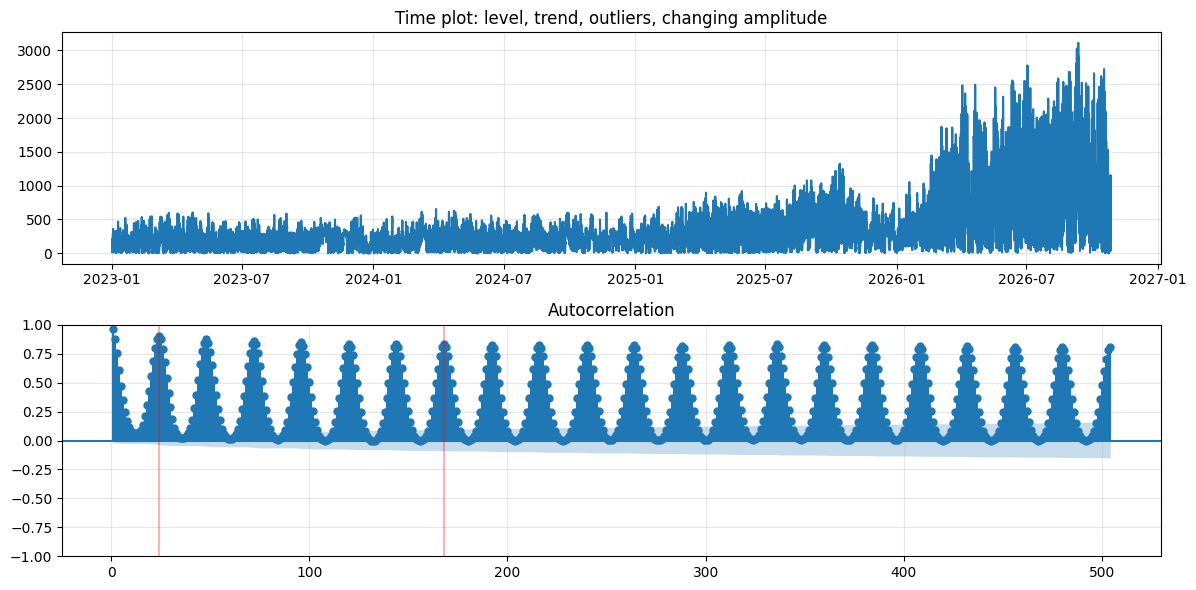

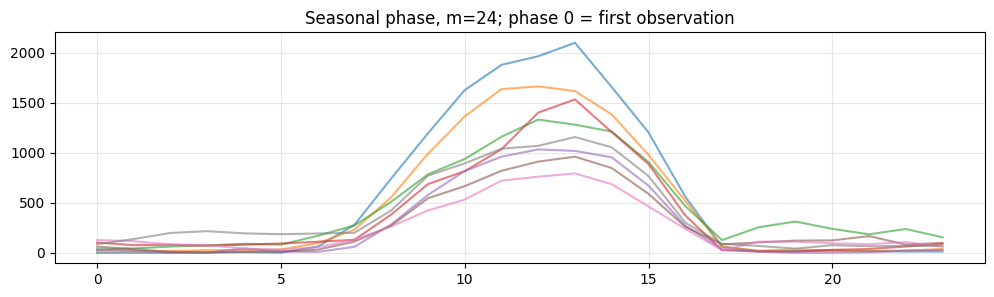

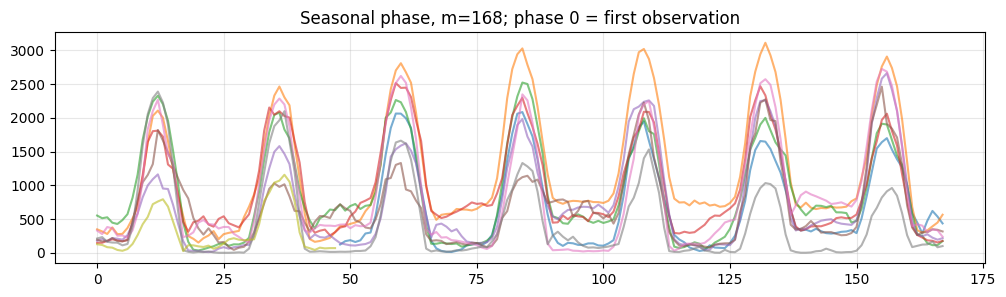

In [114]:
diagnostic_plots(df, periods=[24, 168], max_lags=3*168)
seasonal_profile(df, m=24)
seasonal_profile(df, m=168)

↑ Conclusions:
- The series changes over time. Before 2026, the mean and the seasonal swing were much smaller, but from early 2026 the swing grows drastically, so the earlier years describe a different story. Therefore, I will crop the data.
- Data has very strong daily (24 hours) and weekly (168 hours) seasonality.

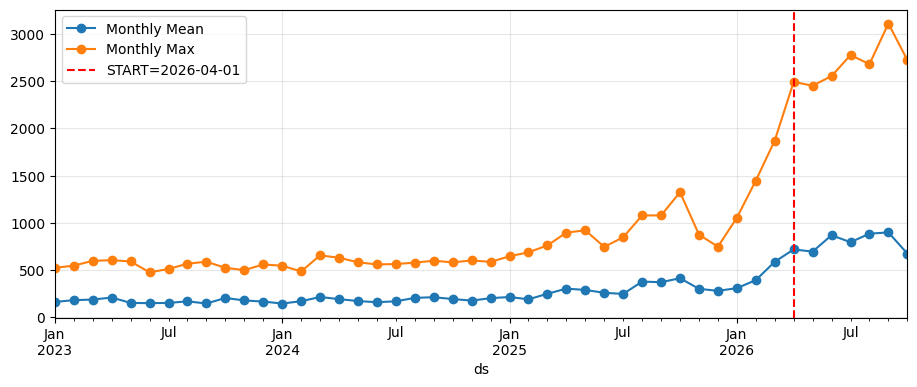

In [94]:
m = df.set_index("ds")["y"].resample("MS").agg(["mean", "max"])
fig, ax = plt.subplots(figsize=(11, 4))
m["mean"].plot(ax=ax, marker="o", label="Monthly Mean")
m["max"].plot(ax=ax, marker="o", label="Monthly Max")
ax.axvline(pd.Timestamp("2026-04-01"), color="red", ls="--", label="START=2026-04-01")
ax.legend(); plt.show()

↑ I chose to crop data at 2026-04-01 and use only the more recent data.

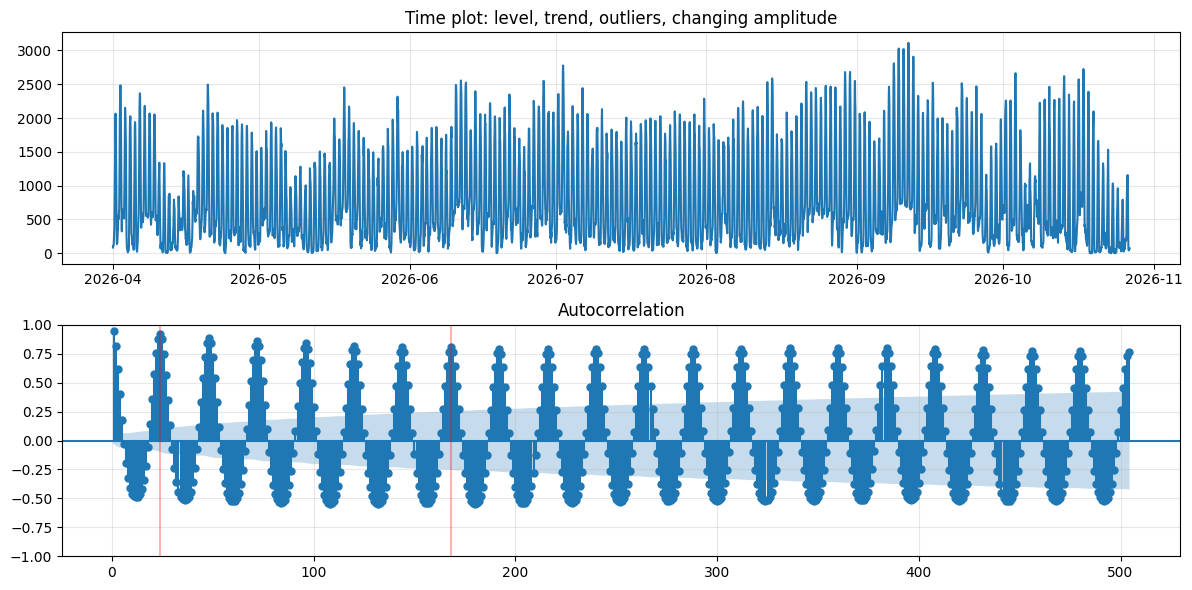

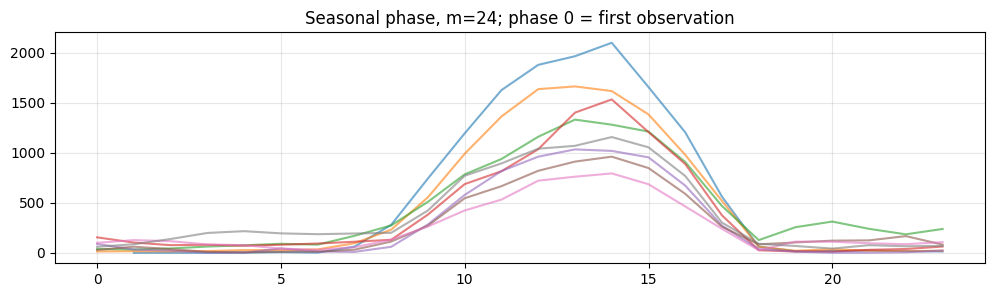

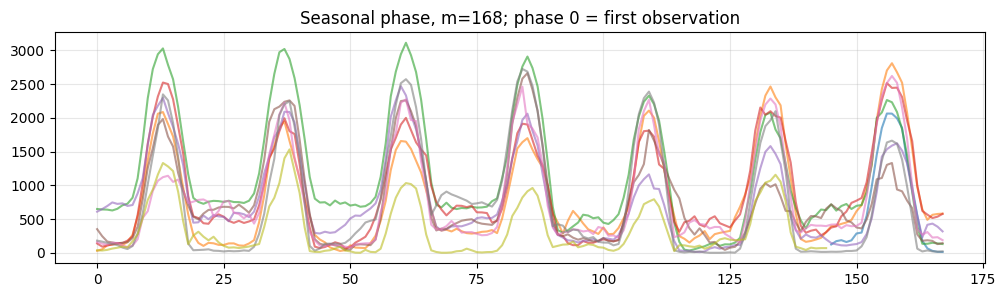

In [95]:
diagnostic_plots(df[df['ds'] >= "2026-04-01"], periods=[24, 168], max_lags=3*168)
seasonal_profile(df[df['ds'] >= "2026-04-01"], m=24)
seasonal_profile(df[df['ds'] >= "2026-04-01"], m=168)

↑ There is no distinct trend, but there is very strong seasonality. The level of the seasonal swing does not seem to altogether increase or decrease.

## 3. Trying different models

In [120]:
import warnings, numpy as np, pandas as pd
from time import perf_counter
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

# ============ 0. ПАРАМЕТРИ ============
START   = "2026-04-01"
STRIDE  = 2          # 1 = щодня; 2-4 якщо важкі моделі повільні
C       = 20         # зсув для log(y + C) і нормалізації
MIN_PAST = 30        # мінімум попередніх вікон для емпіричного інтервалу
RUN_HEAVY = True     # False = лише швидкі моделі

y_all  = data["y"].to_numpy(float)
ds_all = data["ds"].reset_index(drop=True)
n_all  = len(y_all)

# origin = позиція першої години прогнозу, яка має hour == 0
cand = np.where((ds_all.dt.hour == 0) & (ds_all >= START))[0]
cand = cand[(cand >= 24 * 28) & (cand + H <= n_all)]
ORIGINS = cand[::STRIDE]
print(f"вікон: {len(ORIGINS)}, від {ds_all[ORIGINS[0]]} до {ds_all[ORIGINS[-1]]}")

# ============ ВАЖЛИВО: Перераховуємо Y та LV ОДРАЗУ для поточного ORIGINS ============
Y  = np.stack([y_all[o:o + H] for o in ORIGINS])               # (nw, H)
LV = np.array([y_all[o - 168:o].mean() for o in ORIGINS])      # L = середнє за 7 діб

# ============ 1. МОДЕЛІ ============
def m_snaive(hist):            return np.resize(hist[-24:], H)

def _prof(hist, k, agg):
    return agg(hist[-24 * k:].reshape(k, 24), axis=0)

def m_prof(k, agg):
    return lambda hist: np.resize(_prof(hist, k, agg), H)

def m_prof7_level(hist):       # профіль 7д, масштабований під вчорашній рівень
    p = _prof(hist, 7, np.mean)
    return np.resize(p * (hist[-24:].mean() + C) / (p.mean() + C), H)

def m_blend(w):
    return lambda hist: w * m_snaive(hist) + (1 - w) * m_prof(7, np.mean)(hist)

def m_ets(train_days, bt_correct=True):
    def f(hist):
        z = np.log(hist[-24 * train_days:] + C)
        fit = ExponentialSmoothing(z, trend="add", damped_trend=True, seasonal="add",
                                   seasonal_periods=24, initialization_method="estimated").fit()
        mu = fit.forecast(H)
        s2 = np.var(fit.resid) if bt_correct else 0.0
        return np.clip(np.exp(mu + 0.5 * s2) - C, 0, None)
    return f

def _fourier(t, period=24, K=6):
    cols = []
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * t / period), np.cos(2 * np.pi * k * t / period)]
    return np.column_stack(cols)

def _fourier_multi(t, periods=[24, 168], Ks=[4, 2]):
    cols = []
    for period, K in zip(periods, Ks):
        for k in range(1, K + 1):
            cols += [np.sin(2 * np.pi * k * t / period), np.cos(2 * np.pi * k * t / period)]
    return np.column_stack(cols)

def m_harmarma(train_days=28, K=6, order=(2, 0, 1)):
    def f(hist):
        z = np.log(hist[-24 * train_days:] + C)
        t = np.arange(len(z) + H)
        X = _fourier(t, 24, K)
        fit = SARIMAX(z, exog=X[:len(z)], order=order, trend="c").fit(disp=False, maxiter=100)
        mu = fit.forecast(H, exog=X[len(z):])
        s2 = np.var(fit.resid[24:])
        return np.clip(np.exp(mu + 0.5 * s2) - C, 0, None)
    return f

def m_harmarma_weekly(train_days=28, order=(2, 0, 1)):
    def f(hist):
        z = np.log(hist[-24 * train_days:] + C)
        t = np.arange(len(z) + H)
        X = _fourier_multi(t, periods=[24, 168], Ks=[4, 2])
        fit = SARIMAX(z, exog=X[:len(z)], order=order, trend="c").fit(disp=False, maxiter=100)
        mu = fit.forecast(H, exog=X[len(z):])
        s2 = np.var(fit.resid[24:])
        return np.clip(np.exp(mu + 0.5 * s2) - C, 0, None)
    return f

def m_harmarma_d1(train_days=28, K=4, order=(1, 1, 1)):
    def f(hist):
        z = np.log(hist[-24 * train_days:] + C)
        t = np.arange(len(z) + H)
        X = _fourier(t, 24, K)
        fit = SARIMAX(z, exog=X[:len(z)], order=order, trend="n").fit(disp=False, maxiter=100)
        mu = fit.forecast(H, exog=X[len(z):])
        s2 = np.var(fit.resid[24:])
        return np.clip(np.exp(mu + 0.5 * s2) - C, 0, None)
    return f

def m_prof_arma(train_days=14, order=(2, 0, 1)):
    def f(hist):
        prof_base = np.resize(_prof(hist, 7, np.mean), len(hist))
        resid = hist[-24 * train_days:] - prof_base[-24 * train_days:]
        fit = SARIMAX(resid, order=order, trend="c").fit(disp=False, maxiter=100)
        mu_resid = fit.forecast(H)
        prof_future = np.resize(_prof(hist, 7, np.mean), H)
        return np.clip(prof_future + mu_resid, 0, None)
    return f

FAST = {
    "SNaive":        m_snaive,
    "Prof3_mean":    m_prof(3, np.mean),
    "Prof3_median":  m_prof(3, np.median),
    "Prof7_mean":    m_prof(7, np.mean),
    "Prof7_median":  m_prof(7, np.median),
    "Prof7_level":   m_prof7_level,
    "Blend_w0.25":   m_blend(0.25),
    "Blend_w0.50":   m_blend(0.50),
    "Blend_w0.75":   m_blend(0.75),
}

HEAVY = {
    "ETS_14d":              m_ets(14),
    "ETS_28d":              m_ets(28),
    "HarmARMA_K6":          m_harmarma(28, K=6, order=(2, 0, 1)),
    "HarmARMA_K4":          m_harmarma(28, K=4, order=(2, 0, 1)),
    "HarmARMA_K2":          m_harmarma(28, K=2, order=(2, 0, 1)),
    "HarmARMA_Weekly":      m_harmarma_weekly(28, order=(2, 0, 1)),
    "HarmARMA_d1":          m_harmarma_d1(28, K=4, order=(1, 1, 1)),
    "Prof7_ARMA":           m_prof_arma(14, order=(2, 0, 1)),
}

# ============ 2. БЕКТЕСТ: точкові прогнози ============
def run_models(models):
    out = {}
    for name, f in models.items():
        t0 = perf_counter(); P = np.empty((len(ORIGINS), H)); fails = 0
        for i, o in enumerate(ORIGINS):
            try:
                P[i] = f(y_all[:o])
            except Exception:
                P[i] = m_snaive(y_all[:o]); fails += 1
        out[name] = P
        print(f"{name:20s} {perf_counter()-t0:6.1f}s  fallback={fails}")
    return out

PRED = run_models(FAST)
if RUN_HEAVY:
    PRED.update(run_models(HEAVY))
    for base in list(HEAVY.keys()):
        PRED[f"{base}+SNaive"] = 0.5 * PRED[base] + 0.5 * PRED["SNaive"]

# ============ 3. ІНТЕРВАЛ: емпіричні нормалізовані залишки, лише з минулих вікон ============
HRS  = np.arange(H) % 24
DAY  = np.arange(H) // 24
BAND = np.select([(HRS >= 21) | (HRS <= 5), HRS <= 10, HRS <= 16], [0, 1, 2], 3)  # ніч/розгін/пік/вечір
GROUPS = [(b, d) for b in range(4) for d in range(2)]

def add_intervals(P):
    R = (Y - P) / (LV[:, None] + C)                 # знакові нормалізовані залишки
    lo, hi = np.full(P.shape, np.nan), np.full(P.shape, np.nan)
    for k, o in enumerate(ORIGINS):
        avail = np.where(ORIGINS + H <= o)[0]       # вікно j завершилось до origin k
        if len(avail) < MIN_PAST:
            continue
        for b, d in GROUPS:
            m = (BAND == b) & (DAY == d)
            r = R[avail][:, m].ravel()
            q_lo, q_hi = np.quantile(r, [0.025, 0.975])
            lo[k, m] = P[k, m] + q_lo * (LV[k] + C)
            hi[k, m] = P[k, m] + q_hi * (LV[k] + C)
    lo = np.clip(np.minimum(lo, P), 0, None); hi = np.maximum(hi, P)
    return lo, hi

INT = {name: add_intervals(P) for name, P in PRED.items()}

# референс: власний інтервал бенчмарку з шаблону
snaive_native = [snaive(y_all[:o]) for o in ORIGINS]
INT["SNaive(native)"] = (np.stack([s[1] for s in snaive_native]), np.stack([s[2] for s in snaive_native]))
PRED["SNaive(native)"] = PRED["SNaive"]

# ============ 4. МЕТРИКИ ПО ВІКНАХ (all / day1 / day2) ============
valid = ~np.isnan(INT["SNaive"][0]).any(axis=1)     # вікна після розігріву
parts = {"all": slice(0, H), "d1": slice(0, 24), "d2": slice(24, 48)}

rows = []
for name in PRED:
    P = PRED[name]; lo, hi = INT[name]
    for k in np.where(valid)[0]:
        for pn, sl in parts.items():
            a, p, l, u = Y[k, sl], P[k, sl], lo[k, sl], hi[k, sl]
            s = score(a, p, l, u)
            s["rank_score"] = 0.3 * s["RMSE"] + 0.3 * s["MAPE"] + 0.4 * s["Winkler"]
            rows.append(dict(model=name, win=k, part=pn, **s))
res = pd.DataFrame(rows)

# метадані вікон і страти
prev_level = np.array([y_all[o - 24:o].mean() for o in ORIGINS])
meta = pd.DataFrame({"win": np.arange(len(ORIGINS)), "origin": ds_all[ORIGINS].values,
                     "prev_level": prev_level})
meta = meta[valid]
meta["calm"]   = meta["prev_level"] <= meta["prev_level"].quantile(1 / 3)
meta["autumn"] = pd.to_datetime(meta["origin"]).dt.month.isin([9, 10, 11])
meta["last60"] = pd.to_datetime(meta["origin"]) >= pd.to_datetime(meta["origin"]).max() - pd.Timedelta(days=60)
print("поріг 'спокійно' (prev_level):", round(meta["prev_level"].quantile(1/3)), "| тест: ~323")
print(meta[["calm", "autumn", "last60"]].sum().to_dict(), "з", len(meta), "вікон")

# ============ 5. ЗВЕДЕННЯ: відношення до SNaive ============
METR = ["RMSE", "MAPE", "Winkler", "rank_score"]

def summarize(part="all", wins=None, ref="SNaive"):
    d = res[res["part"] == part]
    if wins is not None:
        d = d[d["win"].isin(wins)]
    base = d[d["model"] == ref].set_index("win")[METR]
    out = []
    for name, g in d.groupby("model"):
        g = g.set_index("win")
        r = g[METR] / base.loc[g.index]
        row = {"model": name, "n": len(g), "coverage": g["coverage"].mean()}
        for m in METR:
            row[f"{m}_med"]  = r[m].median()
            row[f"{m}_geo"]  = np.exp(np.log(r[m]).mean())
            row[f"{m}_win%"] = (r[m] < 1).mean() * 100
        out.append(row)
    return pd.DataFrame(out).set_index("model")

full = summarize("all")
print("\n=== ВСІ ВІКНА: відношення до SNaive (<1 = краще) ===")
print(full[["n", "coverage", "RMSE_med", "RMSE_geo", "RMSE_win%", "MAPE_geo", "Winkler_geo", "rank_score_geo", "rank_score_win%"]].round(3).to_string())

abs_tbl = res[res["part"] == "all"].groupby("model")[METR + ["coverage"]].mean()
print("\n=== АБСОЛЮТНІ СЕРЕДНІ (для довідки; домінують великі дні) ===")
print(abs_tbl.round(2).to_string())

# страти: geo ratio (rank_score і RMSE) + coverage
strata = {
    "calm":     (meta.loc[meta.calm,   "win"], "all"),
    "volatile": (meta.loc[~meta.calm,  "win"], "all"),
    "autumn":   (meta.loc[meta.autumn, "win"], "all"),
    "non-autumn": (meta.loc[~meta.autumn, "win"], "all"),
    "last60":   (meta.loc[meta.last60, "win"], "all"),
    "day1":     (meta["win"], "d1"),
    "day2":     (meta["win"], "d2"),
}
tabs = {k: summarize(part, wins) for k, (wins, part) in strata.items()}
geo_rmse  = pd.DataFrame({k: t["RMSE_geo"] for k, t in tabs.items()})
geo_score = pd.DataFrame({k: t["rank_score_geo"] for k, t in tabs.items()})
cov_tbl   = pd.DataFrame({k: t["coverage"] for k, t in tabs.items()})
print("\n=== СТРАТИ: geo-mean RMSE ratio ===");        print(geo_rmse.round(3).to_string())
print("\n=== СТРАТИ: geo-mean rank_score ratio ===");  print(geo_score.round(3).to_string())
print("\n=== СТРАТИ: coverage (ціль 0.92–0.98) ===");  print(cov_tbl.round(3).to_string())

# правило проходження: не гірше за SNaive у calm та last60 (за RMSE і rank_score)
passed = ((geo_rmse["calm"] <= 1) & (geo_rmse["last60"] <= 1) &
          (geo_score["calm"] <= 1) & (geo_score["last60"] <= 1))
print("\n=== ПРОХОДЯТЬ (calm & last60 ≤ 1 за RMSE і rank_score) ===")
print(passed[passed].index.tolist())

вікон: 104, від 2026-04-01 00:00:00 до 2026-10-24 00:00:00
SNaive                  0.0s  fallback=0
Prof3_mean              0.0s  fallback=0
Prof3_median            0.0s  fallback=0
Prof7_mean              0.0s  fallback=0
Prof7_median            0.0s  fallback=0
Prof7_level             0.0s  fallback=0
Blend_w0.25             0.0s  fallback=0
Blend_w0.50             0.0s  fallback=0
Blend_w0.75             0.0s  fallback=0
ETS_14d                 6.9s  fallback=0
ETS_28d                10.9s  fallback=0
HarmARMA_K6            66.0s  fallback=0
HarmARMA_K4            44.4s  fallback=0
HarmARMA_K2            19.2s  fallback=0
HarmARMA_Weekly        65.0s  fallback=0
HarmARMA_d1            20.7s  fallback=0
Prof7_ARMA              4.6s  fallback=0
поріг 'спокійно' (prev_level): 750 | тест: ~323
{'calm': 26, 'autumn': 27, 'last60': 31} з 74 вікон

=== ВСІ ВІКНА: відношення до SNaive (<1 = краще) ===
                         n  coverage  RMSE_med  RMSE_geo  RMSE_win%  MAPE_geo  Winkler_geo

Graph to search for parameters for HarmARMA:

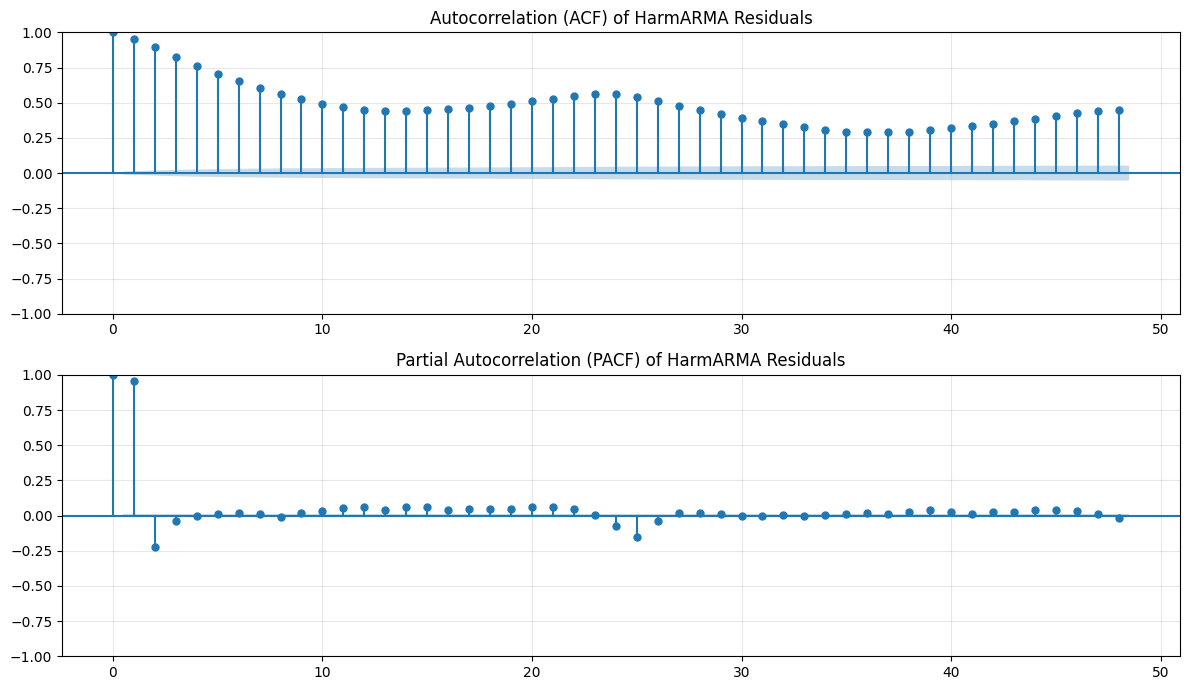

In [117]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Початкові параметри
K_fourier = 4
period = 24

# 2. Логарифмування часового ряду (відповідно до логіки вашої моделі)
z_all = np.log(y_all + C)

# 3. Генерація матриці гармонік Фур'є (X) та доповнення її константою (інтерцептом)
t = np.arange(len(z_all))
X = _fourier(t, period=period, K=K_fourier)
X_design = np.column_stack([np.ones(len(t)), X])  # додаємо колонку з 1 для константи (a_0)

# 4. Оцінка коефіцієнтів детермінованої гармонійної частини (МНК / Least Squares)
weights, _, _, _ = np.linalg.lstsq(X_design, z_all, rcond=None)

# 5. Розрахунок відновленої гармонійної моделі та виділення залишків
deterministic_trend = X_design @ weights
resid = z_all - deterministic_trend

# 6. Побудова графіків ACF та PACF залишків
fig, ax = plt.subplots(2, 1, figsize=(12, 7))

# Графік ACF для вибору порядку MA (q)
plot_acf(resid, lags=48, ax=ax[0], title="Autocorrelation (ACF) of HarmARMA Residuals")
ax[0].grid(True, alpha=0.3)

# Графік PACF для вибору порядку AR (p)
plot_pacf(resid, lags=48, ax=ax[1], title="Partial Autocorrelation (PACF) of HarmARMA Residuals", method="ywm")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Submission

Model **`**HarmARMA_K4+SNaive**`**

In [132]:
NAME = "HarmARMA_K4+SNaive"

# Точка: та сама формула, що в бектесті, але від кінця всієї історії
p_harm = HEAVY["HarmARMA_K4"](y_all)
p_sn   = m_snaive(y_all)
point  = 0.5 * p_harm + 0.5 * p_sn

# Інтервал: нормалізовані залишки всіх завершених вікон бектесту
R      = (Y - PRED[NAME]) / (LV[:, None] + C)
LV_now = y_all[-168:].mean()

# Вікна бектесту починаються з 00:00, а справжній прогноз з 01:00 → зсув на 1 крок
j = np.minimum(np.arange(H) + 1, H - 1)

lo = np.empty(H); hi = np.empty(H)
for b, d in GROUPS:
    m_bt = (BAND == b) & (DAY == d)
    q_lo, q_hi = np.quantile(R[:, m_bt].ravel(), [0.025, 0.975])
    m_fin = (BAND[j] == b) & (DAY[j] == d)
    lo[m_fin] = point[m_fin] + q_lo * (LV_now + C)
    hi[m_fin] = point[m_fin] + q_hi * (LV_now + C)

fc_final = point
lo_final = np.clip(np.minimum(lo, point), 0, None)
hi_final = np.maximum(hi, point)

assert len(fc_final) == len(lo_final) == len(hi_final) == H
assert np.isfinite(fc_final).all() and np.isfinite(lo_final).all() and np.isfinite(hi_final).all()
assert (lo_final <= fc_final).all() and (fc_final <= hi_final).all()
print("вікон для інтервалу:", len(R), "| рівень вчорашнього дня:", round(LV_now, 1))
print(pd.DataFrame({"ds": FUTURE, "forecast": fc_final, "lo": lo_final, "hi": hi_final}).round(1).head(6).to_string(index=False))

вікон для інтервалу: 104 | рівень вчорашнього дня: 362.9
                 ds  forecast   lo    hi
2026-10-27 01:00:00      78.1  0.0 253.5
2026-10-27 02:00:00     106.7  0.0 282.1
2026-10-27 03:00:00     140.3  8.4 315.7
2026-10-27 04:00:00     149.3 17.4 324.7
2026-10-27 05:00:00     135.9  4.0 311.3
2026-10-27 06:00:00     135.0  0.0 313.7


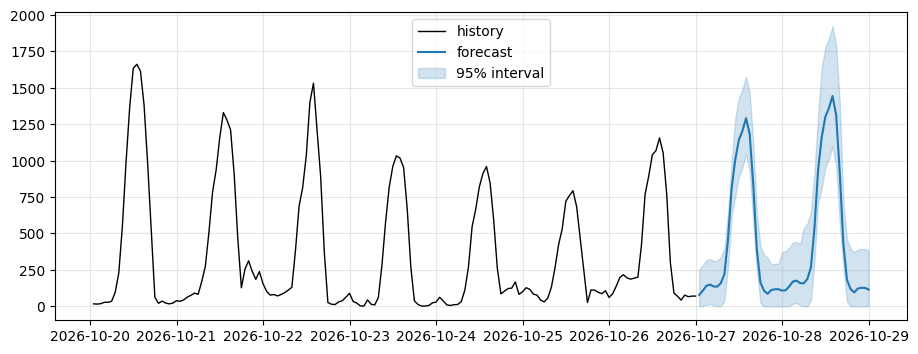

In [133]:
forecast, lower_95, upper_95 = fc_final, lo_final, hi_final

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [134]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved ALDOSHYNA_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>